**Запуск в Google Colab.**

```
!unzip -q bh-yield-prediction.zip
%cd bh-yield-prediction/notebooks
!pip install -q -r ../requirements.txt
```

При локальном запуске эта инструкция не нужна.

# Предсказание выхода реакции Бухвальда–Хартвига

Вопрос: **обобщается ли модель выхода реакции на компоненты, которых не было в обучении?**
Данные: HTE-скрининг C–N кросс-сочетания (Ahneman et al., *Science* 2018), 3955 реакций.

Запуск: `pip install -r requirements.txt`, затем *Run All*. Нужен `git` (для скачивания данных).
Ячейка с `evaluate.main()` считает модели по трём схемам валидации и занимает 1–3 минуты.

In [6]:
import sys
from pathlib import Path

def find_root():
    here = Path.cwd()
    for p in [here, *here.parents]:                      # ноутбук лежит внутри проекта
        if (p / "src" / "data.py").exists():
            return p
    for pattern in ("*/src/data.py", "*/*/src/data.py"):  # проект лежит рядом / глубже
        hits = sorted(here.glob(pattern))
        if hits:
            return hits[0].parents[1]
    raise FileNotFoundError(
        f"Не нашёл папку проекта (src/data.py) от {here}. Распакуй архив и выполни "
        "в отдельной ячейке: %cd bh-yield-prediction/notebooks (в Colab: !unzip -q bh-yield-prediction.zip)")

ROOT = find_root()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import data, download_data, evaluate, importance

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "axes.axisbelow": True})
BLUE, ORANGE, AQUA, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#9a9993"
print("project root:", ROOT)

project root: /content/bh-yield-prediction


## 1. Данные

In [7]:
download_data.main()          # скачает xlsx в data/raw, если его ещё нет
df = data.load_processed()    # проверки целостности внутри; пишет data/processed/reactions.csv
print(df.shape)
df.head()

saved /content/bh-yield-prediction/data/raw/Dreher_and_Doyle_input_data.xlsx (2.1 MB)
(3955, 11)


,ligand,additive,base,aryl_halide,yield_pct,halogen,aryl_core,ligand_id,base_id,additive_id,core_id
0,CC(C)C(C=C(C(C)C)C=C1C(C)C)=C1C2=C(P([C@@]3(C[...,CC1=CC(C)=NO1,CN(C)P(N(C)C)(N(C)C)=NP(N(C)C)(N(C)C)=NCC,ClC1=NC=CC=C1,70.410458,Cl,C1=NC=CC=C1,L4,B2,A10,C5
1,CC(C)C(C=C(C(C)C)C=C1C(C)C)=C1C2=C(P([C@@]3(C[...,O=C(OC)C1=CC=NO1,CN(C)P(N(C)C)(N(C)C)=NP(N(C)C)(N(C)C)=NCC,BrC1=NC=CC=C1,11.064457,Br,C1=NC=CC=C1,L4,B2,A20,C5
2,CC(C)C(C=C(C(C)C)C=C1C(C)C)=C1C2=C(P(C3CCCCC3)...,O=C(OC)C1=CC=NO1,CN(C)P(N(C)C)(N(C)C)=NP(N(C)C)(N(C)C)=NCC,IC1=CC=C(CC)C=C1,10.223550,I,C1=CC=C(CC)C=C1,L3,B2,A20,C2
3,CC(C)C(C=C(C(C)C)C=C1C(C)C)=C1C2=C(P(C(C)(C)C)...,CCOC(C1=CON=C1)=O,CN1CCCN2C1=NCCC2,ClC1=CC=C(C(F)(F)F)C=C1,20.083383,Cl,C1=CC=C(C(F)(F)F)C=C1,L1,B3,A16,C1
4,CC(C)C(C=C(C(C)C)C=C1C(C)C)=C1C2=C(P([C@@]3(C[...,CC1=CC(C)=NO1,CN1CCCN2C1=NCCC2,ClC1=CC=C(OC)C=C1,0.492663,Cl,C1=CC=C(OC)C=C1,L4,B3,A10,C3


In [8]:
print(df[["ligand_id", "additive_id", "base_id", "core_id", "halogen"]].nunique())
df["yield_pct"].describe().round(1)

ligand_id       4
additive_id    22
base_id         3
core_id         5
halogen         3
dtype: int64


,yield_pct
count,3955.0
mean,33.1
std,27.3
min,0.0
25%,7.9
50%,28.8
75%,53.3
max,100.0


В исходной книге все листы содержат одни и те же 3955 реакций в разном порядке, поэтому читается один лист.
Листы `Test1–4` не используются: часть добавок из их тестовых частей встречается и в обучающих,
так что это не чистая проверка на новые добавки. Строгие групповые сплиты делаются ниже самостоятельно.

## 2. Разведочный анализ

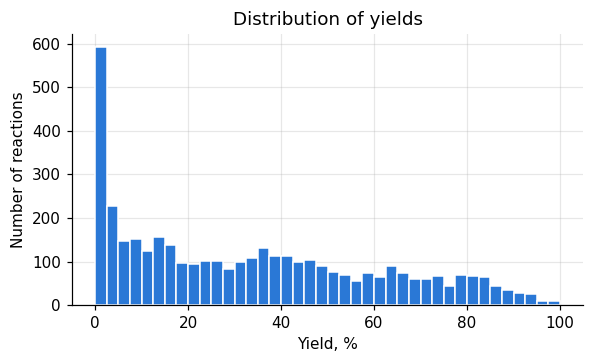

zero yield: 6.0% | >=70%: 13.2%


In [9]:
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.hist(df["yield_pct"], bins=40, color=BLUE, edgecolor="white")
ax.set_xlabel("Yield, %"); ax.set_ylabel("Number of reactions")
ax.set_title("Distribution of yields")
plt.show()
print("zero yield:", f"{(df['yield_pct'] == 0).mean():.1%}", "| >=70%:", f"{(df['yield_pct'] >= 70).mean():.1%}")

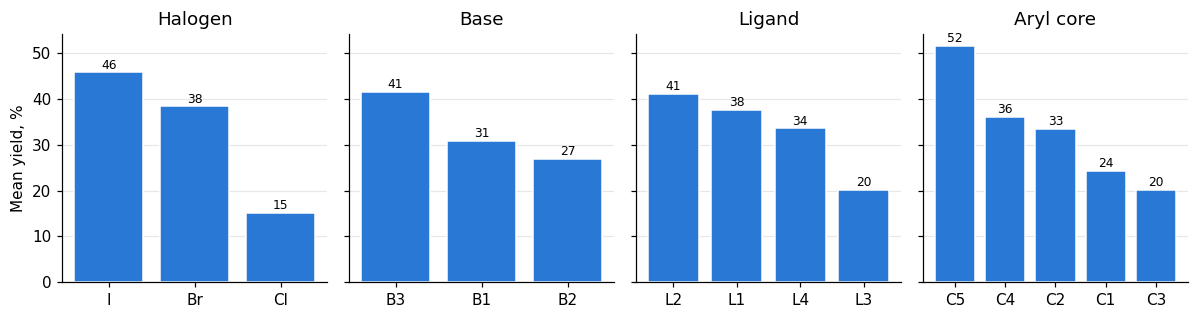

In [10]:
panels = [("halogen", "Halogen"), ("base_id", "Base"), ("ligand_id", "Ligand"), ("core_id", "Aryl core")]
fig, axes = plt.subplots(1, 4, figsize=(11, 3), sharey=True)
for ax, (col, title) in zip(axes, panels):
    m = df.groupby(col)["yield_pct"].mean().sort_values(ascending=False)
    ax.bar(m.index, m.values, color=BLUE, edgecolor="white")
    for i, v in enumerate(m.values):
        ax.text(i, v + 0.8, f"{v:.0f}", ha="center", fontsize=8)
    ax.set_title(title); ax.grid(axis="x", visible=False)
axes[0].set_ylabel("Mean yield, %")
plt.tight_layout(); plt.show()

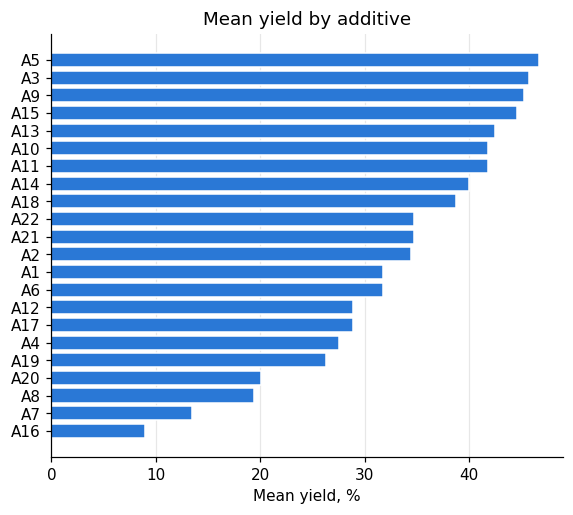

In [11]:
m = df.groupby("additive_id")["yield_pct"].mean().sort_values()
fig, ax = plt.subplots(figsize=(6, 5))
ax.barh(m.index, m.values, color=BLUE, edgecolor="white")
ax.set_xlabel("Mean yield, %"); ax.set_title("Mean yield by additive"); ax.grid(axis="y", visible=False)
plt.show()

In [12]:
p = df.pivot_table(index="ligand_id", columns="base_id", values="yield_pct", aggfunc="mean").round(1)
p

base_id,B1,B2,B3
ligand_id,,,
L1,35.2,29.6,47.9
L2,39.6,32.4,51.3
L3,19.4,18.9,22.2
L4,29.2,27.0,44.4


## 3. Модели и три схемы валидации

- **random 70/30** — 10 случайных разбиений (обычная практика);
- **leave-additive-out** — каждая из 22 добавок целиком уходит в тест;
- **leave-core-out** — каждое из 5 ароматических ядер целиком уходит в тест.

Признаки — one-hot компонентов; он не умеет обобщать на новые категории (новая категория = строка нулей),
и групповые схемы измеряют именно это.

In [13]:
evaluate.main()   # пишет reports/metrics.csv и reports/oof_predictions.csv, 1-3 минуты

            scheme                   model     R2   RMSE    MAE
      random 70/30           mean baseline -0.003 27.222 23.241
      random 70/30         ridge (one-hot)  0.659 15.868 12.639
      random 70/30           random forest  0.899  8.611  5.688
      random 70/30 hist. gradient boosting  0.901  8.554  6.128
leave-additive-out           mean baseline -0.014 27.482 23.533
leave-additive-out         ridge (one-hot)  0.498 19.328 15.455
leave-additive-out           random forest  0.514 19.018 12.368
leave-additive-out hist. gradient boosting  0.590 17.473 12.291
    leave-core-out           mean baseline -0.090 28.485 24.095
    leave-core-out         ridge (one-hot)  0.364 21.768 17.841
    leave-core-out           random forest  0.218 24.133 18.739
    leave-core-out hist. gradient boosting  0.298 22.870 17.859


In [14]:
metrics = pd.read_csv(ROOT / "reports" / "metrics.csv")
table = metrics.pivot(index="scheme", columns="model", values="R2").round(3)
table = table.loc[["random 70/30", "leave-additive-out", "leave-core-out"],
                  ["mean baseline", "ridge (one-hot)", "random forest", "hist. gradient boosting"]]
table

model,mean baseline,ridge (one-hot),random forest,hist. gradient boosting
scheme,,,,
random 70/30,-0.003,0.659,0.899,0.901
leave-additive-out,-0.014,0.498,0.514,0.590
leave-core-out,-0.090,0.364,0.218,0.298


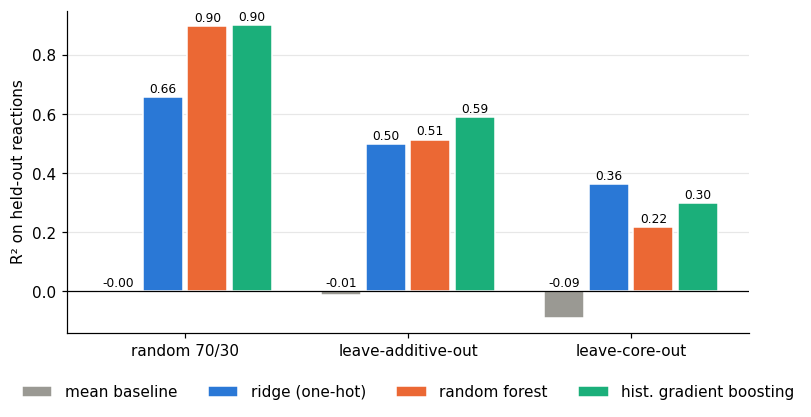

In [15]:
schemes = list(table.index); models = list(table.columns)
colors = [GRAY, BLUE, ORANGE, AQUA]
fig, ax = plt.subplots(figsize=(8, 3.8)); w = 0.2
for k, (mod, col) in enumerate(zip(models, colors)):
    xs = np.arange(len(schemes)) + (k - 1.5) * w
    ax.bar(xs, table[mod].values, width=w - 0.02, color=col, edgecolor="white", label=mod)
    for x, v in zip(xs, table[mod].values):
        ax.text(x, max(v, 0) + 0.015, f"{v:.2f}", ha="center", fontsize=8)
ax.axhline(0, color="black", lw=0.8)
ax.set_xticks(range(len(schemes)), schemes); ax.set_ylabel("R² on held-out reactions")
ax.grid(axis="x", visible=False)
ax.legend(frameon=False, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.12))
plt.show()

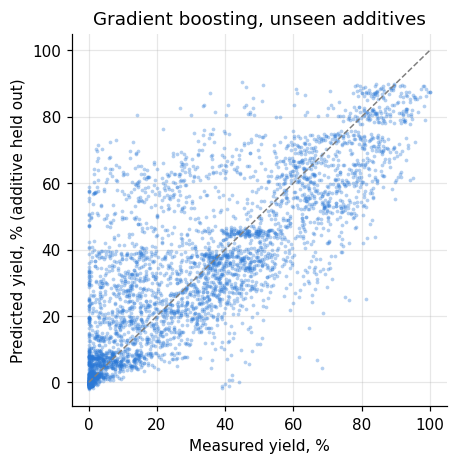

In [16]:
oof = pd.read_csv(ROOT / "reports" / "oof_predictions.csv")
sub = oof[(oof.scheme == "leave-additive-out") & (oof.model == "hist. gradient boosting")]
fig, ax = plt.subplots(figsize=(4.4, 4.4))
ax.scatter(sub["y_true"], sub["y_pred"], s=6, color=BLUE, alpha=0.35, linewidths=0)
ax.plot([0, 100], [0, 100], "--", color="gray", lw=1)
ax.set_xlabel("Measured yield, %"); ax.set_ylabel("Predicted yield, % (additive held out)")
ax.set_title("Gradient boosting, unseen additives")
plt.show()

## 4. На что опирается модель

Групповая permutation importance: компонент целиком перемешивается в тесте, смотрим падение R².
Это описание поведения модели, а не причинные эффекты.

In [17]:
importance.main()   # пишет reports/permutation_importance.csv

            mean    std
component              
halogen    0.670  0.039
aryl core  0.561  0.027
additive   0.488  0.027
ligand     0.328  0.021
base       0.298  0.018


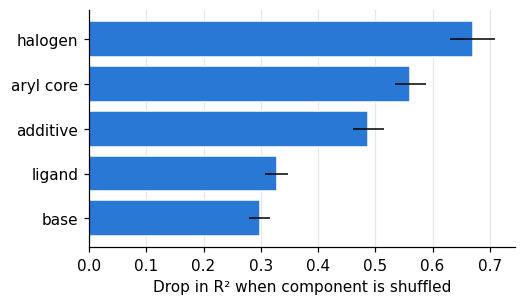

In [18]:
imp = pd.read_csv(ROOT / "reports" / "permutation_importance.csv", index_col=0).sort_values("mean")
fig, ax = plt.subplots(figsize=(5, 2.8))
ax.barh(imp.index, imp["mean"], xerr=imp["std"], color=BLUE, edgecolor="white", error_kw={"lw": 1})
ax.set_xlabel("Drop in R² when component is shuffled"); ax.grid(axis="y", visible=False)
plt.show()

## 5. Дескрипторы вместо one-hot (нужен RDKit)

При one-hot новая добавка или новое ядро — строка нулей, о ней модель ничего не знает.
Здесь добавка и ароматическое ядро описываются числами (молекулярная масса, logP, TPSA, число атомов
по элементам; отдельно — счётчики подструктур Morgan), а лиганд, основание и галоген остаются one-hot.
Схемы валидации те же. Ridge масштабирует дескрипторы внутри каждого фолда обучения, без утечки из теста.

Расчёт занимает 2–4 минуты.

In [19]:
try:
    import rdkit
except ImportError:                      # например, в Colab без предустановленного RDKit
    import subprocess
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "rdkit"], check=True)
    import rdkit
print("RDKit", rdkit.__version__)

import descriptors, evaluate_descriptors
res = evaluate_descriptors.main()        # пишет reports/metrics_descriptors.csv

RDKit 2026.09.1
rdkit physchem: 35 features (25 descriptor columns)
morgan counts: 134 features (124 descriptor columns)
      features             scheme                   model     R2   RMSE    MAE
rdkit physchem       random 70/30           mean baseline -0.003 27.222 23.241
rdkit physchem       random 70/30                   ridge  0.556 18.108 14.493
rdkit physchem       random 70/30           random forest  0.529 18.660 12.716
rdkit physchem       random 70/30 hist. gradient boosting  0.741 13.841  9.247
rdkit physchem leave-additive-out           mean baseline -0.014 27.482 23.533
rdkit physchem leave-additive-out                   ridge  0.221 24.079 19.955
rdkit physchem leave-additive-out           random forest  0.379 21.502 15.241
rdkit physchem leave-additive-out hist. gradient boosting  0.378 21.513 15.413
rdkit physchem     leave-core-out           mean baseline -0.090 28.485 24.095
rdkit physchem     leave-core-out                   ridge  0.264 23.403 18.921
rdkit phys

In [20]:
base = pd.read_csv(ROOT / "reports" / "metrics.csv").assign(features="one-hot")
base["model"] = base["model"].replace({"ridge (one-hot)": "ridge"})
desc = pd.read_csv(ROOT / "reports" / "metrics_descriptors.csv")
allm = pd.concat([base, desc], ignore_index=True)

order_s = ["random 70/30", "leave-additive-out", "leave-core-out"]
order_f = ["one-hot", "rdkit physchem", "morgan counts"]
order_m = ["ridge", "random forest", "hist. gradient boosting"]
tbl = allm[allm.model.isin(order_m)].pivot_table(index=["scheme", "features"], columns="model", values="R2")
tbl = tbl.reindex(pd.MultiIndex.from_product([order_s, order_f]))[order_m].round(3)
tbl

model                              ridge  random forest  \
random 70/30       one-hot         0.659          0.899   
                   rdkit physchem  0.556          0.529   
                   morgan counts   0.629          0.729   
leave-additive-out one-hot         0.498          0.514   
                   rdkit physchem  0.221          0.379   
                   morgan counts   0.485          0.654   
leave-core-out     one-hot         0.364          0.218   
                   rdkit physchem  0.264          0.287   
                   morgan counts   0.396          0.300   

model                              hist. gradient boosting  
random 70/30       one-hot                           0.901  
                   rdkit physchem                    0.741  
                   morgan counts                     0.809  
leave-additive-out one-hot                           0.590  
                   rdkit physchem                    0.378  
                   morgan counts                     0.658  
leave-core-out     one-hot                           0.298  
                   rdkit physchem                    0.356  
                   morgan counts                     0.328

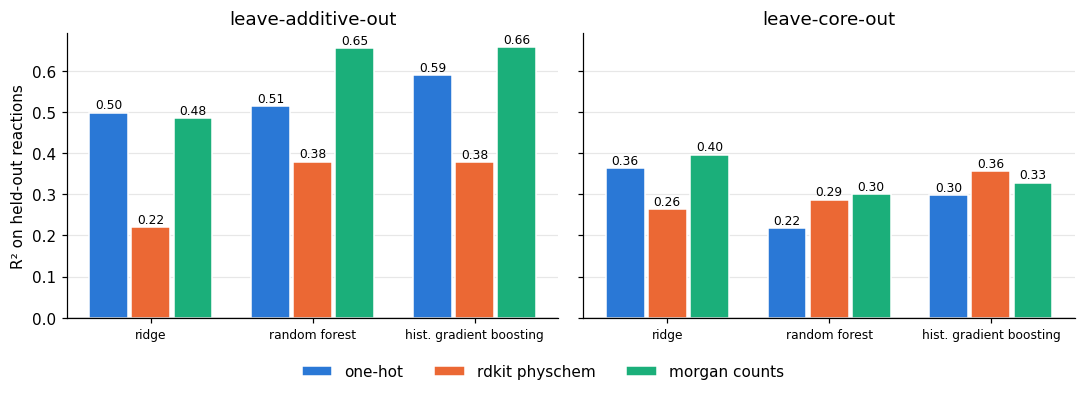

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
colors = {"one-hot": BLUE, "rdkit physchem": ORANGE, "morgan counts": AQUA}
w = 0.26
for ax, scheme in zip(axes, order_s[1:]):
    for k, feat in enumerate(order_f):
        vals = tbl.loc[(scheme, feat), order_m].to_numpy(dtype=float)
        xs = np.arange(len(order_m)) + (k - 1) * w
        ax.bar(xs, vals, width=w - 0.02, color=colors[feat], edgecolor="white", label=feat)
        for x, v in zip(xs, vals):
            ax.text(x, max(v, 0) + 0.01, f"{v:.2f}", ha="center", fontsize=8)
    ax.axhline(0, color="black", lw=0.8)
    ax.set_xticks(range(len(order_m)), order_m, fontsize=8)
    ax.set_title(scheme); ax.grid(axis="x", visible=False)
axes[0].set_ylabel("R² on held-out reactions")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=3, frameon=False)
plt.tight_layout(rect=(0, 0.08, 1, 1)); plt.show()

**Вывод по дескрипторам**

- **Счётчики подструктур Morgan немного помогают на новой добавке.** Лучший результат вырос с 0.59 (бустинг,
  one-hot) до 0.66 (бустинг, Morgan); у случайного леса прирост заметнее: 0.51 → 0.65.
  Простые физико-химические дескрипторы, наоборот, ухудшили результат: лучший R² 0.38.
- **На новом ядре выигрыша не видно.** Лучший one-hot (ridge) даёт 0.36, лучший с дескрипторами 0.40
  (ridge, Morgan), физико-химические дают 0.36 (бустинг). Фолдов всего 5, поэтому разницу в 0.03–0.04
  от шума не отличить.
- **У дескрипторов есть цена: на случайном сплите они хуже.** Лучший R² 0.90 у one-hot, 0.81 у Morgan и 0.74
  у физико-химических дескрипторов. One-hot прямо кодирует, какой это компонент, а по дескрипторам модели
  приходится это восстанавливать.
- **Почему физико-химические дескрипторы не помогли (гипотеза, в работе не проверялась).** 22 добавки — близкие аналоги,
  и масса, logP и TPSA различают их слабо, тогда как для выхода, вероятно, важна конкретная подструктура,
  которую ловят счётчики Morgan.
- **Осторожность.** Это один запуск без доверительных интервалов; «лучший результат» выбран по тем же тестовым
  фолдам, что и оценка, поэтому для всех наборов он слегка оптимистичен. Прирост 0.07 на 22 фолдах заметен,
  но не доказан; проверка на других разбиениях — в разделе 6.

## 6. Устойчивость сравнения

Таблица в разделе 5 — это один набор разбиений. Здесь сравнение повторяется на многих разных разбиениях,
и для каждого считается **разница с one-hot на том же разбиении**, чтобы лёгкие и трудные разбиения не мешали:

- **новая добавка:** 30 случайных разбиений, каждый раз 6 из 22 добавок целиком уходят в тест;
- **новое ядро:** R² отдельно для каждого из 5 ядер, когда оно отложено.

Разбиения пересекаются, поэтому разброс по ним показывает, насколько результат зависит от выбора отложенных
добавок, а не является доверительным интервалом. Расчёт занимает 5–10 минут.

In [22]:
import robustness
rob_add, rob_core = robustness.main()    # пишет reports/robustness_*.csv

additive splits: 1/30
additive splits: 2/30
additive splits: 3/30
additive splits: 4/30
additive splits: 5/30
additive splits: 6/30
additive splits: 7/30
additive splits: 8/30
additive splits: 9/30
additive splits: 10/30
additive splits: 11/30
additive splits: 12/30
additive splits: 13/30
additive splits: 14/30
additive splits: 15/30
additive splits: 16/30
additive splits: 17/30
additive splits: 18/30
additive splits: 19/30
additive splits: 20/30
additive splits: 21/30
additive splits: 22/30
additive splits: 23/30
additive splits: 24/30
additive splits: 25/30
additive splits: 26/30
additive splits: 27/30
additive splits: 28/30
additive splits: 29/30
additive splits: 30/30
core folds: held out C1
core folds: held out C2
core folds: held out C3
core folds: held out C4
core folds: held out C5

Additive splits: R2 across splits
                                        mean   std    min   max
model                   features                               
hist. gradient boosting morgan count

In [23]:
print(f"Разбиений: {rob_add['split'].nunique()}; в тесте по {rob_add['n_test_additives'].iloc[0]} добавок из 22")
rob_add.groupby(["model", "features"])["R2"].agg(["mean", "std", "min", "max"]).round(3)

Разбиений: 30; в тесте по 6 добавок из 22


mean    std    min    max
model                   features                                  
hist. gradient boosting morgan counts   0.598  0.095  0.389  0.757
                        one-hot         0.552  0.140  0.105  0.759
                        rdkit physchem  0.379  0.123  0.103  0.554
random forest           morgan counts   0.590  0.105  0.405  0.740
                        one-hot         0.488  0.159 -0.017  0.740
                        rdkit physchem  0.362  0.118  0.103  0.541
ridge                   morgan counts   0.458  0.094  0.177  0.588
                        one-hot         0.479  0.086  0.240  0.601
                        rdkit physchem  0.150  0.257 -0.610  0.465

In [24]:
robustness.paired_summary(rob_add, "split").round(3)

,model,features,n_units,mean_diff,sd_diff,win_rate
0,hist. gradient boosting,morgan counts,30,0.045,0.086,0.800
1,hist. gradient boosting,rdkit physchem,30,-0.173,0.118,0.067
2,random forest,morgan counts,30,0.102,0.119,0.833
3,random forest,rdkit physchem,30,-0.126,0.119,0.133
4,ridge,morgan counts,30,-0.021,0.038,0.267
5,ridge,rdkit physchem,30,-0.329,0.284,0.000


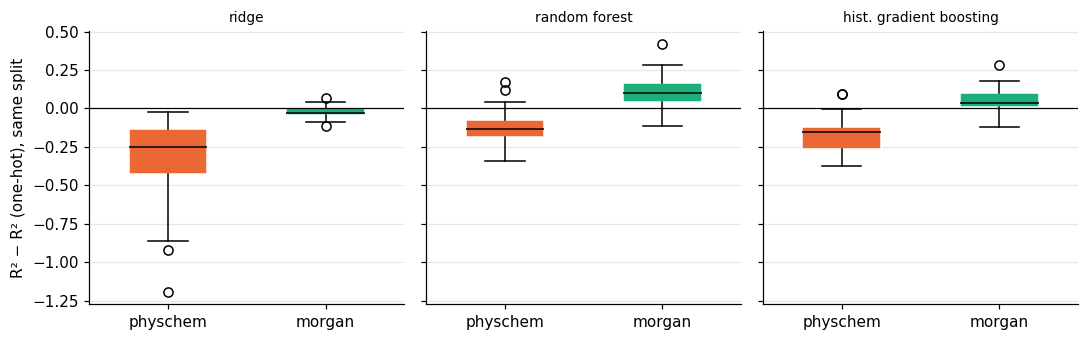

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3.2), sharey=True)
palette = {"rdkit physchem": ORANGE, "morgan counts": AQUA}
for ax, model in zip(axes, robustness.MODELS):
    wide = rob_add[rob_add.model == model].pivot(index="split", columns="features", values="R2")
    diffs = [wide[f] - wide["one-hot"] for f in palette]
    bp = ax.boxplot(diffs, patch_artist=True, widths=0.5, medianprops={"color": "black"})
    for patch, color in zip(bp["boxes"], palette.values()):
        patch.set_facecolor(color); patch.set_edgecolor("white")
    ax.axhline(0, color="black", lw=0.8)
    ax.set_xticks([1, 2], ["physchem", "morgan"]); ax.set_title(model, fontsize=9)
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("R² − R² (one-hot), same split")
plt.tight_layout(); plt.show()

In [26]:
rob_core.pivot_table(index=["model", "features"], columns="held_out_core", values="R2").round(3)

held_out_core                              C1     C2     C3     C4     C5
model                   features                                         
hist. gradient boosting morgan counts  -0.564  0.602  0.129  0.179  0.050
                        one-hot        -0.864  0.628 -0.023  0.456 -0.284
                        rdkit physchem  0.278  0.556  0.029  0.172  0.044
random forest           morgan counts  -0.665  0.607  0.123  0.131 -0.005
                        one-hot        -1.222  0.587 -0.239  0.388 -0.324
                        rdkit physchem  0.049  0.486 -0.056  0.122 -0.046
ridge                   morgan counts  -0.171  0.587  0.073  0.307  0.162
                        one-hot        -0.237  0.614 -0.084  0.560 -0.226
                        rdkit physchem  0.067  0.282 -0.247  0.247  0.022

In [27]:
robustness.paired_summary(rob_core, "held_out_core").round(3)

,model,features,n_units,mean_diff,sd_diff,win_rate
0,hist. gradient boosting,morgan counts,5,0.096,0.252,0.6
1,hist. gradient boosting,rdkit physchem,5,0.233,0.554,0.6
2,random forest,morgan counts,5,0.200,0.320,0.8
3,random forest,rdkit physchem,5,0.273,0.599,0.6
4,ridge,morgan counts,5,0.066,0.236,0.6
5,ridge,rdkit physchem,5,-0.051,0.306,0.4


**Вывод по устойчивости**

Как читать: `mean_diff` — средняя разность R² с one-hot на тех же разбиениях, `win_rate` — доля разбиений
(или ядер), где набор признаков лучше one-hot.

- **Новая добавка: Morgan лучше one-hot у деревьев, но выигрыш скромнее, чем казалось по таблице раздела 5.**
  На 30 разбиениях средняя разность: бустинг +0.045 (лучше в 24 из 30 разбиений), случайный лес +0.10 (в 25 из 30);
  у ridge −0.02 (лучше лишь в 8 из 30). Прирост 0.07 у бустинга в разделе 5 был выше среднего по разбиениям (0.045).
- **Главное преимущество Morgan — стабильность.** Разброс R² по разбиениям меньше (std 0.095 против 0.14 у бустинга,
  0.105 против 0.16 у леса), а худшее разбиение заметно лучше: 0.389 против 0.105 у бустинга, 0.405 против −0.017 у леса.
- **Физико-химические дескрипторы на новой добавке стабильно хуже one-hot:** разность −0.17 (бустинг), −0.13 (лес),
  −0.33 (ridge); лучше one-hot лишь в 2, 4 и 0 разбиениях из 30.
- **Новое ядро: наборы признаков различить нельзя.** Результат определяется тем, какое ядро отложено: C2 предсказывается
  лучше остальных у всех моделей (R² 0.5–0.6, кроме ridge с физико-химическими), а C1 хуже всех у one-hot
  (от −0.24 до −1.22) и у Morgan (от −0.17 до −0.67), тогда как физико-химические дескрипторы на нём заметно
  лучше (от 0.05 до 0.28). Разброс разностей по 5 ядрам (0.24–0.32
  у Morgan) больше их средних (0.07–0.20). Кажущийся выигрыш физико-химических дескрипторов у деревьев (+0.23 и +0.27)
  почти целиком даёт одно ядро C1: без него разность близка к нулю (≈0.01 у бустинга, ≈0.02 у леса).
  Проверка причины — в разделе 7: сдвиг среднего уровня объясняет около 40% потерь на новом ядре.
- **Осторожность.** Разбиения пересекаются, поэтому доли побед (80–83%) завышают уверенность; это разброс по разбиениям,
  а не доверительный интервал. Ядер всего 5, любые выводы о новых ядрах предварительные.

## 7. Откуда потери на новом ядре: сдвиг уровня выхода

Гипотеза: для ядра, которого модель не видела, ей не известен средний выход этого ядра, а R² на отложенном
ядре штрафует именно за этот сдвиг. Проверка: ошибка на каждой отложенной группе (ядре или добавке) раскладывается
на смещение среднего и остальное (MSE = смещение² + дисперсия ошибки), а R² пересчитывается после вычитания
смещения из прогнозов.

Вычитание использует истинное среднее отложенной группы, так что это диагностика, а не рабочая модель.
Анализ идёт по предсказаниям one-hot моделей из `reports/oof_predictions.csv`; для наборов с дескрипторами
такие предсказания не сохранялись.

In [28]:
import offset_analysis
by_group, pooled = offset_analysis.main()   # читает reports/oof_predictions.csv, пишет reports/offset_analysis_*.csv

Pooled R2: raw vs with per-group offset removed
            scheme                   model  r2_pooled  r2_pooled_offset_removed  r2_group_mean_only
leave-additive-out hist. gradient boosting      0.590                     0.763               0.146
leave-additive-out           random forest      0.514                     0.694               0.146
leave-additive-out         ridge (one-hot)      0.498                     0.659               0.146
    leave-core-out hist. gradient boosting      0.298                     0.599               0.159
    leave-core-out           random forest      0.218                     0.557               0.159
    leave-core-out         ridge (one-hot)      0.364                     0.612               0.159

Leave-core-out, by held-out core
                  model group   n  mean_yield    bias     mse  bias_share_of_mse  r2_raw  r2_offset_removed  spearman_within_group  mean_pred  train_mean_yield  pred_to_true_std
hist. gradient boosting    C1 790      2

In [29]:
pooled.assign(recovered=lambda d: d["r2_pooled_offset_removed"] - d["r2_pooled"]).round(3)

               scheme                    model  r2_pooled  r2_pooled_offset_removed  r2_group_mean_only  recovered
0  leave-additive-out  hist. gradient boosting      0.590                     0.763               0.146      0.173
1  leave-additive-out            random forest      0.514                     0.694               0.146      0.180
2  leave-additive-out          ridge (one-hot)      0.498                     0.659               0.146      0.161
3      leave-core-out  hist. gradient boosting      0.298                     0.599               0.159      0.301
4      leave-core-out            random forest      0.218                     0.557               0.159      0.340
5      leave-core-out          ridge (one-hot)      0.364                     0.612               0.159      0.248

In [30]:
core = by_group[by_group.scheme == "leave-core-out"].copy()
core["pred_minus_train_mean"] = core["mean_pred"] - core["train_mean_yield"]
core[["model", "group", "mean_yield", "train_mean_yield", "mean_pred", "pred_minus_train_mean",
      "bias_share_of_mse", "r2_raw", "r2_offset_removed", "pred_to_true_std"]].round(2)

                      model group  mean_yield  train_mean_yield  mean_pred  pred_minus_train_mean  bias_share_of_mse  r2_raw  r2_offset_removed  pred_to_true_std
66  hist. gradient boosting    C1       24.36             35.26      34.40                  -0.86               0.23   -0.86              -0.43              1.93
67  hist. gradient boosting    C2       33.39             33.01      25.89                  -7.11               0.18    0.63               0.69              0.58
68  hist. gradient boosting    C3       20.13             36.33      36.12                  -0.21               0.62   -0.02               0.61              1.34
69  hist. gradient boosting    C4       36.01             32.35      22.78                  -9.57               0.36    0.46               0.65              0.65
70  hist. gradient boosting    C5       51.51             28.47      28.42                  -0.05               0.55   -0.28               0.43              0.73
71            random forest 

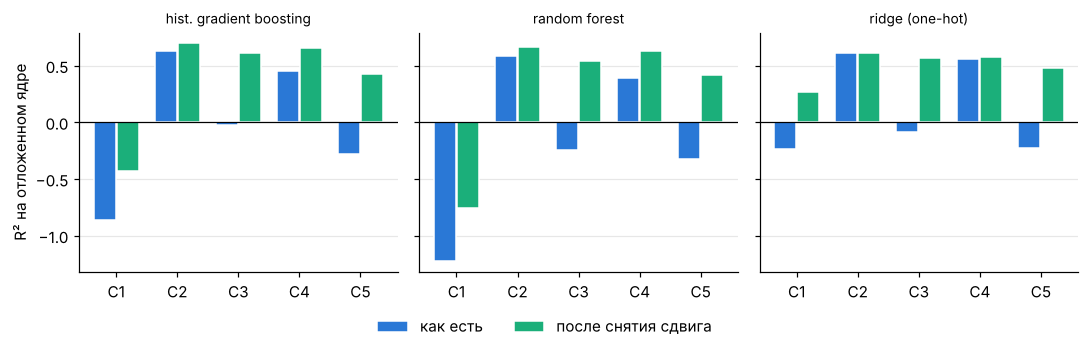

In [31]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3.2), sharey=True)
cores = sorted(core.group.unique()); w = 0.38
for ax, (model, g) in zip(axes, core.groupby("model")):
    g = g.set_index("group").loc[cores]
    x = np.arange(len(cores))
    ax.bar(x - w / 2, g["r2_raw"], width=w - 0.02, color=BLUE, edgecolor="white", label="как есть")
    ax.bar(x + w / 2, g["r2_offset_removed"], width=w - 0.02, color=AQUA, edgecolor="white", label="после снятия сдвига")
    ax.axhline(0, color="black", lw=0.8)
    ax.set_xticks(x, cores); ax.set_title(model, fontsize=9); ax.grid(axis="x", visible=False)
axes[0].set_ylabel("R² на отложенном ядре")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=2, frameon=False)
plt.tight_layout(rect=(0, 0.08, 1, 1)); plt.show()

**Вывод по сдвигу уровня** (числа раздела посчитаны по предсказаниям one-hot моделей; при повторном запуске у случайного леса
они могут отличаться в третьем знаке)

- **Гипотеза подтверждается частично: около 40% потерянного качества на новом ядре — это сдвиг уровня.**
  Объединённый R² на новом ядре после снятия сдвига: бустинг 0.30 → 0.60, лес 0.22 → 0.56, ridge 0.36 → 0.61
  (возвращается 0.25–0.34, то есть 39–43% от потерянного). На новой добавке эффект слабее: 0.59 → 0.76,
  0.51 → 0.69, 0.50 → 0.66 (32–42%).
- **Механизм виден напрямую у ridge:** на незнакомом ядре он выдаёт средний выход остальных ядер, разница
  со средним по обучению не больше 0.1 на всех пяти ядрах. Поэтому ядра с низким выходом он завышает
  (C3 на +16, C1 на +10), а ядро с самым высоким выходом занижает (C5 на −23). Деревья на C1, C3 и C5 делают то же
  самое (в пределах 1.6 от среднего по обучению), но на C2 и C4 занижают уровень ещё на 7–11 пунктов.
- **Оставшиеся потери — это ошибки внутри ядра (R² после снятия сдвига 0.4–0.7 на четырёх ядрах из пяти).** Порядок реакций внутри ядра
  предсказывается неплохо (корреляция Спирмена 0.64–0.90), но масштаб разброса неверный: на C2, C4 и C5
  прогнозы «сжаты» (стандартное отклонение 0.55–0.73 от истинного), а на C1 «раздуты» (1.4 у ridge,
  1.9–2.1 у деревьев). Поэтому C1 остаётся отрицательным у деревьев даже после снятия сдвига (−0.43 и −0.76).
- **Это объясняет, почему ridge лучше леса на новом ядре (0.36 против 0.22):** преимущество почти целиком
  создают C1 (R² −0.24 против −1.22: деревья сильнее раздувают разброс) и C4 (0.56 против 0.39–0.46: деревья
  занижают уровень на 10–11 пунктов относительно среднего по обучению, а ridge нет).
- **Осторожность.** Это диагностика на 5 ядрах и одном датасете; объяснение для деревьев (почему именно на C2 и C4
  они занижают уровень) не исследовано.

## 8. Выводы и ограничения

- **Случайный сплит завышает качество.** Градиентный бустинг даёт R² 0.90 при случайном разбиении, 0.59 на новой
  добавке и 0.30 на новом ароматическом ядре. Модель хорошо воспроизводит комбинации, похожие на обучающие,
  и заметно хуже переносится на новую химию.
- **На что опирается модель.** Падение R² при перемешивании компонента: галоген 0.67, ароматическое ядро 0.56,
  добавка 0.49, лиганд 0.33, основание 0.30. Это согласуется с разведочным анализом: в среднем Cl даёт 15% выхода,
  Br 38%, I 46%. Это описание поведения модели, а не причинные эффекты.
- **На новом ядре линейная Ridge (0.36) лучше случайного леса (0.22).** Разбор в разделе 7 показал, что преимущество почти целиком создают два ядра: на C1 деревья раздувают разброс прогнозов (в 1.9–2.1 раза против 1.4 у ridge), на C4 занижают уровень выхода на 10–11 пунктов относительно среднего по обучению.
- **Около 40% потерь на новом ядре — сдвиг уровня выхода (раздел 7).** Для незнакомого ядра модель не знает его среднего выхода: ridge выдаёт среднее по остальным ядрам. После снятия сдвига объединённый R² растёт с 0.30 до 0.60 у бустинга; остальное — ошибки масштаба разброса внутри ядра.
- **Дескрипторы (разделы 5 и 6).** Счётчики подструктур Morgan на новой добавке дают умеренный выигрыш у деревьев: на 30 разбиениях в среднем +0.05 R² у бустинга и +0.10 у леса (лучше one-hot в 24 и 25 разбиениях из 30), у ridge выигрыша нет; кроме того, они уменьшают разброс и повышают худший результат. На новом ядре наборы признаков различить нельзя: результат определяется тем, какое из 5 ядер отложено. Цена — на случайном сплите качество ниже (0.81 против 0.90). Простые физико-химические дескрипторы на новой добавке стабильно хуже one-hot.
- Мало уровней: 4 лиганда, 3 основания, 5 ядер; в leave-core-out всего 5 фолдов, оценка шумная, доверительных
  интервалов нет.
- Один набор условий (полный факториальный HTE одной лаборатории): перенос на другие реакции не проверен.
- Гиперпараметры по умолчанию, поэтому мелкие различия между моделями (например, 0.51 и 0.59 на новой добавке)
  не стоит трактовать как окончательные.
- Возможное развитие: SHAP вместо permutation importance; датасет Suzuki–Miyaura из того же репозитория как проверка переноса; квантово-химические дескрипторы.